Prepoznavanje saobraćajnih znakova je ključna komponenta u savremenim automobilskim sistemima asistencije vozaču (ADAS) i autonomnim vozilima. Cilj ovog projekta je da se trenira model dubokog učenja koji na osnovu slike prepoznaje tip saobraćajnog znaka.

Koristiće se javno dostupan skup podataka GTSRB (German Traffic Sign Recognition Benchmark), koji sadrži slike saobraćajnih znakova iz 43 različite kategorije.

**Ciljevi projekta:**
- Pripremiti i analizirati skup podataka
- Implementirati i trenirati konvolutivnu neuronsku mrežu (CNN)
- Evaluirati model i vizualizovati rezultate

**Očekivani rezultat:** Model koji pouzdano klasifikuje saobraćajne znakove na osnovu slike, uz što veću tačnost na test skupu.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import zipfile
zip_path = '/content/drive/MyDrive/Data.zip'
extract_path = '/content/data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

Otvaranje skupa podataka sa google diska

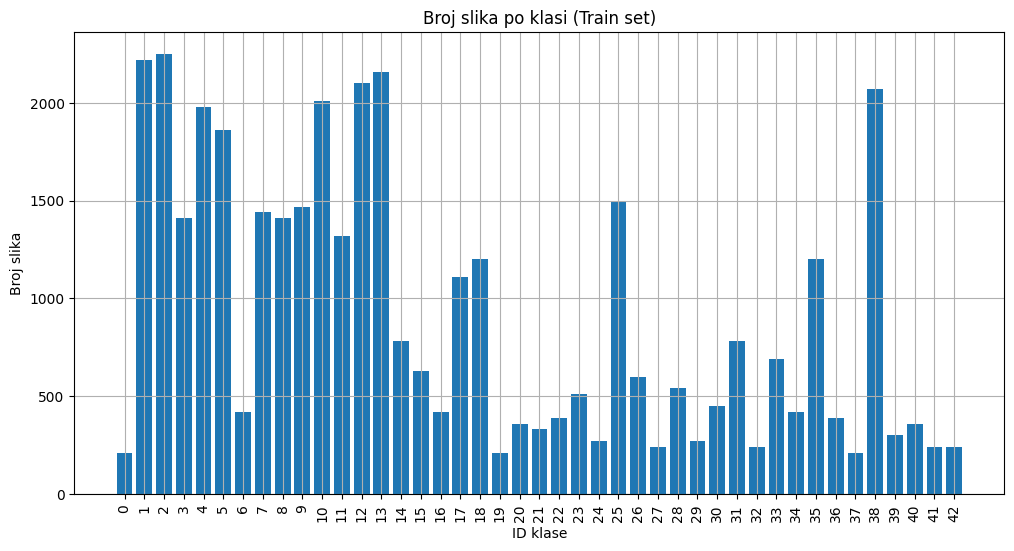

In [5]:
import os
import matplotlib.pyplot as plt

train_dir = './data/Data/Train'

class_counts = {}
for class_id in sorted(os.listdir(train_dir), key=lambda x: int(x)):
    class_path = os.path.join(train_dir, class_id)
    if os.path.isdir(class_path):
        class_counts[class_id] = len(os.listdir(class_path))

plt.figure(figsize=(12, 6))
plt.bar(class_counts.keys(), class_counts.values())
plt.title('Broj slika po klasi (Train set)')
plt.xlabel('ID klase')
plt.ylabel('Broj slika')
plt.xticks(rotation=90)
plt.grid()
plt.show()

Train folder sadrži slike saobraćajnih znakova raspoređene u 43 različite klase. Svaka klasa predstavlja jedan tip znaka (npr. ograničenje brzine, zabrana preticanja, opasnost itd.), i svaka od tih klasa sadrži slike koje pripadaju toj klasi. Broj slika po klasi nije jednak. Neke klase imaju više od 1000 primera, dok druge imaju manje od 200...

In [6]:
import shutil
import random

balanced_dir = './data_balanced'
os.makedirs(balanced_dir, exist_ok=True)

num_samples_per_class = 200

for class_id in sorted(os.listdir(train_dir), key=lambda x: int(x)):
    class_path = os.path.join(train_dir, class_id)
    if os.path.isdir(class_path):
        images = os.listdir(class_path)
        random.shuffle(images)
        selected_images = images[:num_samples_per_class]

        dest_class_path = os.path.join(balanced_dir, class_id)
        os.makedirs(dest_class_path, exist_ok=True)

        for img_name in selected_images:
            src = os.path.join(class_path, img_name)
            dst = os.path.join(dest_class_path, img_name)
            shutil.copyfile(src, dst)

print("Napravljen balansirani skup u", balanced_dir)
train_dir = balanced_dir

Napravljen balansirani skup u ./data_balanced


Ovaj kod kreira balansirani skup podataka tako što za svaku klasu iz originalnog trening skupa nasumično bira po 200 slika i kopira ih u novi folder data_balanced. Time se postiže ravnoteža među klasama kako bi se sprečilo da model favorizuje one sa više primera. Nakon toga, nova putanja train_dir se postavlja na balansirani skup.

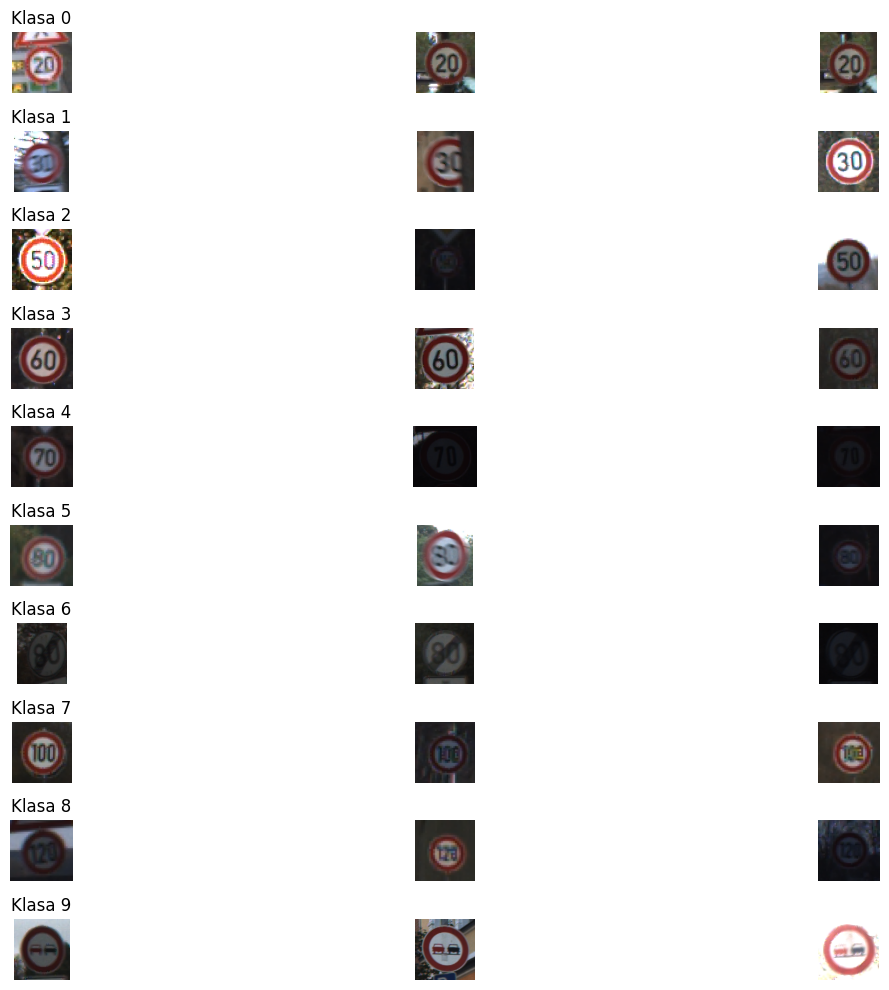

In [7]:
import cv2
import numpy as np

def show_examples(train_dir, examples_per_class=3):
    plt.figure(figsize=(15, 10))
    class_ids = sorted(os.listdir(train_dir), key=lambda x: int(x))

    for idx, class_id in enumerate(class_ids[:10]):
        class_path = os.path.join(train_dir, class_id)
        image_files = os.listdir(class_path)[:examples_per_class]

        for i, img_name in enumerate(image_files):
            img_path = os.path.join(class_path, img_name)
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            plt.subplot(10, examples_per_class, idx * examples_per_class + i + 1)
            plt.imshow(img)
            plt.axis('off')
            if i == 0:
                plt.title(f'Klasa {class_id}')

    plt.tight_layout()
    plt.show()

show_examples(train_dir)

Ovo je prikaz prvih 10 klasa i po 3 slike iz svake od njih

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (32, 32)  # Standardna dimenzija za GTSRB (može i 64x64)

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2  # 80% train, 20% validacija
)

Ovde se koristi ImageDataGenerator iz Keras biblioteke kako bi se slike pripremile za treniranje modela. Pomoću rescale=1./255 vrši se normalizacija piksela (vrednosti od 0 do 1), a pomoću validation_split=0.2 deli se skup na 80% za treniranje i 20% za validaciju.

In [9]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)


Found 6880 images belonging to 43 classes.
Found 1720 images belonging to 43 classes.


Pomoću flow_from_directory kreiraju se generatori koji automatski učitavaju slike iz foldera. train_generator sadrži 80% slika za treniranje, dok val_generator sadrži 20% za validaciju. Slike se menjaju u veličinu IMG_SIZE, grupišu u pakete po 32 slike (batch_size=32), a class_mode='categorical' koristi se jer se radi o višeklasnoj klasifikaciji (43 klase).

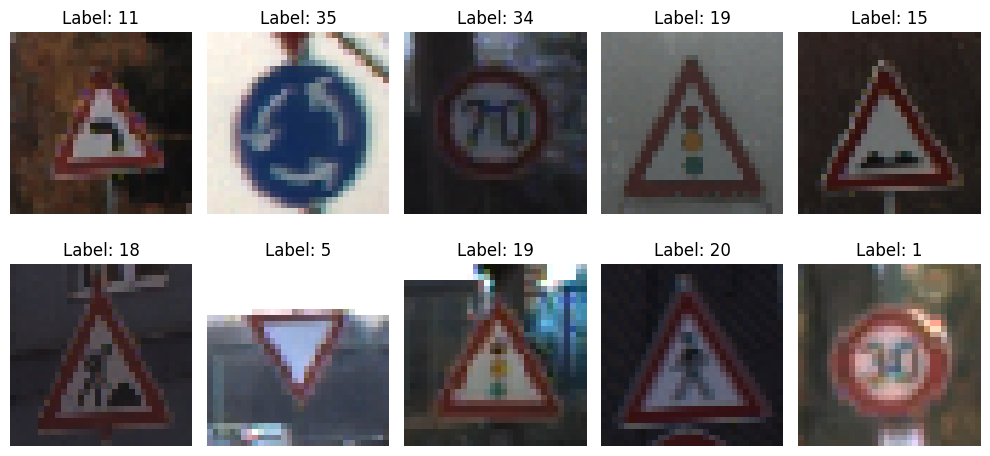

In [10]:
import matplotlib.pyplot as plt

images, labels = next(train_generator)

plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(images[i])
    plt.title(f"Label: {labels[i].argmax()}")
    plt.axis('off')
plt.tight_layout()
plt.show()


Vizualizuje se 10 nasumičnih slika iz trenirajućeg skupa. Svaka slika prikazana je zajedno sa pripadajućom klasom (labelom), koja se dobija pomoću argmax() jer su labele u obliku "one-hot" vektora. Ovo pomaže u proveri da su slike ispravno učitane i da klase odgovaraju vizuelnom sadržaju

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),  # sprečava preobučavanje
    Dense(43, activation='softmax')  # imamo 43 klase
])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Definisan je CNN model (konvoluciona neuronska mreža) pomoću Sequential API-ja. Model ima tri konvoluciona bloka (Conv2D + MaxPooling2D) za izdvajanje karakteristika sa slika. Nakon spljoštavanja (Flatten), sledi potpuno povezan sloj (Dense) sa 128 neurona i Dropout slojem radi sprečavanja preobučavanja. Na kraju, Dense sloj sa 43 izlaza i softmax aktivacijom klasifikuje sliku u jednu od 43 klase saobraćajnih znakova

In [12]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


Model se kompajlira sa Adam optimizatorom, koji automatski prilagođava brzinu učenja tokom treniranja. Funkcija gubitka categorical_crossentropy koristi se zato što imamo višeklasnu klasifikaciju sa one-hot enkodovanim labelama. Kao mera performansi koristi se tačnost (accuracy).

In [13]:
history = model.fit(
    train_generator,
    epochs=30,
    validation_data=val_generator
)


Epoch 1/30
215/215 ━━━━━━━━━━━━━━━━━━━━ 12s 49ms/step - accuracy: 0.0653 - loss: 3.4833 - val_accuracy: 0.2110 - val_loss: 2.8118
Epoch 2/30
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - accuracy: 0.3346 - loss: 2.2339 - val_accuracy: 0.4814 - val_loss: 1.7438
Epoch 3/30
215/215 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.5810 - loss: 1.3442 - val_accuracy: 0.6552 - val_loss: 1.1461
Epoch 4/30
215/215 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.7170 - loss: 0.8891 - val_accuracy: 0.7273 - val_loss: 0.9359
Epoch 5/30
215/215 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.7907 - loss: 0.6478 - val_accuracy: 0.8192 - val_loss: 0.7542
Epoch 6/30
215/215 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.8369 - loss: 0.4980 - val_accuracy: 0.8128 - val_loss: 0.6665
Epoch 7/30
215/215 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - accuracy: 0.8725 - loss: 0.3873 - val_accuracy: 0.8471 - val_loss: 0.5919
Epoch 8/30
215/215 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.9010 - loss: 0.3120 - va

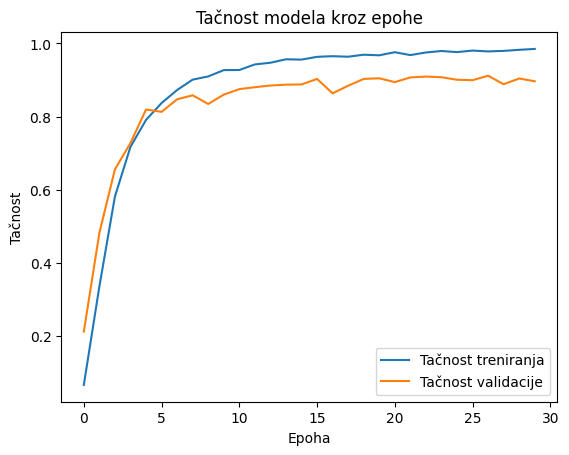

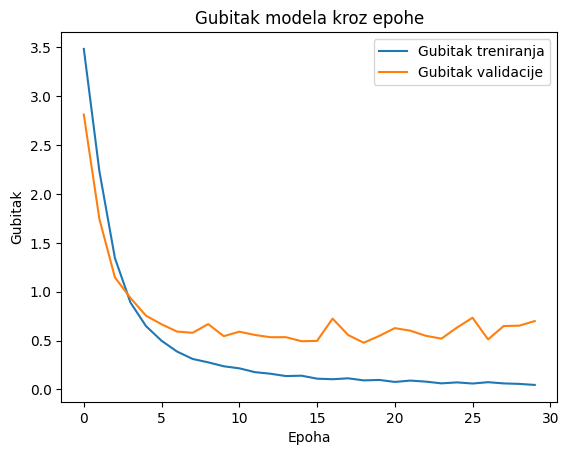

In [14]:
import matplotlib.pyplot as plt

# Accuracy
plt.plot(history.history['accuracy'], label='Tačnost treniranja')
plt.plot(history.history['val_accuracy'], label='Tačnost validacije')
plt.title('Tačnost modela kroz epohe')
plt.xlabel('Epoha')
plt.ylabel('Tačnost')
plt.legend()
plt.show()

# Loss
plt.plot(history.history['loss'], label='Gubitak treniranja')
plt.plot(history.history['val_loss'], label='Gubitak validacije')
plt.title('Gubitak modela kroz epohe')
plt.xlabel('Epoha')
plt.ylabel('Gubitak')
plt.legend()
plt.show()


Model se trenira nad balansiranim skupom korišćenjem funkcije fit(). Treniranje traje 30 epoha, a posmatra se i tačnost i gubitak (loss) na validacionom skupu nakon svake epohe. Na osnovu prikazanih rezultata, tačnost modela značajno raste već nakon nekoliko epoha, što pokazuje da model uspešno uči i generalizuje prepoznavanje saobraćajnih znakova

In [15]:
import pandas as pd
import numpy as np
import os
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tqdm import tqdm

# Učitavanje CSV fajla
test_df = pd.read_csv('./data/Data/Test.csv')

# Lista za slike i labele
X_test = []
y_test = []

IMG_SIZE = (32, 32)

for i in tqdm(range(len(test_df))):
    img_path = './data/Data/' + test_df['Path'][i]
    image = load_img(img_path, target_size=IMG_SIZE)
    image = img_to_array(image)
    image = image / 255.0  # normalizacija
    X_test.append(image)
    y_test.append(test_df['ClassId'][i])

# Konvertovanje u numpy nizove
X_test = np.array(X_test)
y_test = np.array(y_test)


100%|██████████| 12630/12630 [00:05<00:00, 2323.70it/s]


In [16]:
# Predikcija
y_pred = model.predict(X_test)

# Dobijanje indeksa predviđenih klasa
y_pred_indices = np.argmax(y_pred, axis=1)

# Mapiranje indeksa nazad na originalne ID-jeve klasa
index_to_class = {
    v: int(k) for k, v in train_generator.class_indices.items()
}

y_pred_classes = np.array([
    index_to_class[idx] for idx in y_pred_indices
])


395/395 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step


Ovaj deo koda učitava test skup koristeći informacije iz Test.csv fajla. Svaka slika se učitava, skalira na veličinu 32x32 piksela i normalizuje (vrednosti piksela se dele sa 255). Nakon toga, model vrši predikciju klasa za test slike. Funkcija argmax se koristi da se iz softmax izlaza modela izabere klasa sa najvećom verovatnoćom kao finalna predikcija

Tačnost na test skupu: 0.9082343626286619


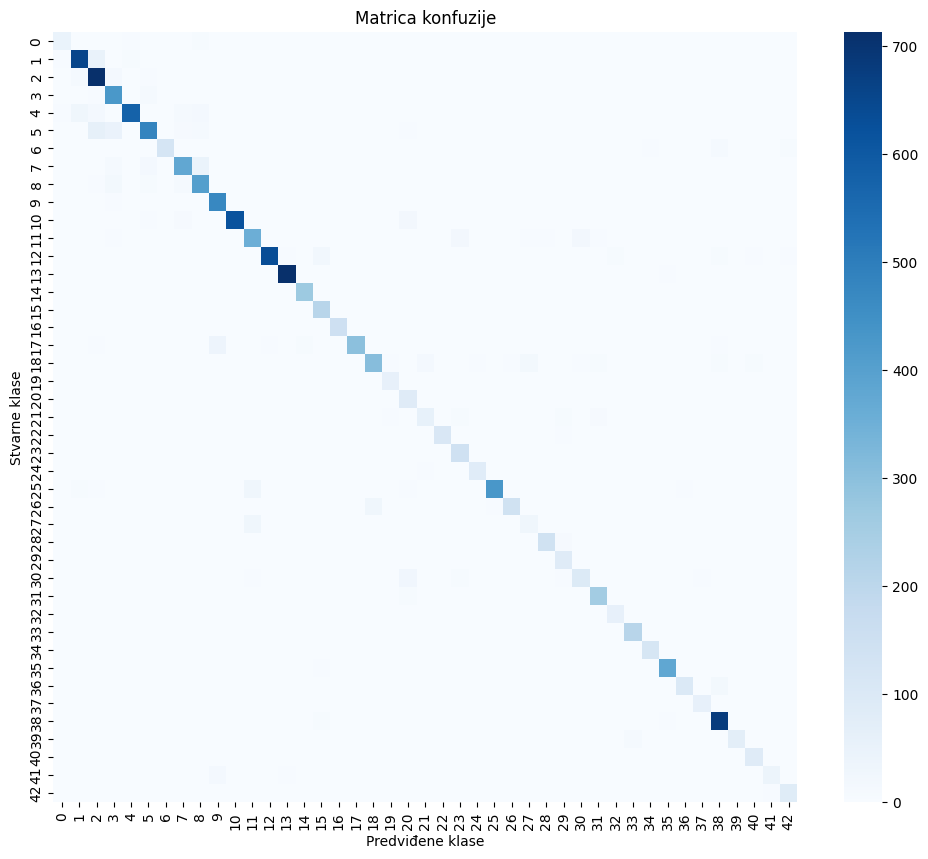

Izveštaj o klasifikaciji:

              precision    recall  f1-score   support

           0       0.89      0.78      0.83        60
           1       0.93      0.91      0.92       720
           2       0.83      0.95      0.89       750
           3       0.80      0.95      0.87       450
           4       0.97      0.87      0.92       660
           5       0.92      0.77      0.84       630
           6       0.98      0.83      0.90       150
           7       0.88      0.84      0.86       450
           8       0.83      0.90      0.86       450
           9       0.89      0.99      0.93       480
          10       0.99      0.94      0.96       660
          11       0.85      0.85      0.85       420
          12       0.98      0.92      0.95       690
          13       0.98      0.99      0.99       720
          14       0.97      1.00      0.99       270
          15       0.84      1.00      0.91       210
          16       0.99      1.00      0.99       150


In [17]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Ukupna tačnost
print("Tačnost na test skupu:", accuracy_score(y_test, y_pred_classes))

# Matrica konfuzije
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, cmap='Blues')
plt.title('Matrica konfuzije')
plt.xlabel('Predviđene klase')
plt.ylabel('Stvarne klase')
plt.show()

# Izveštaj o klasifikaciji
print("Izveštaj o klasifikaciji:\n")
print(classification_report(y_test, y_pred_classes))


U ovom projektu obrađena je klasifikacija saobraćajnih znakova korišćenjem konvolutivne neuronske mreže (CNN) na skupu podataka GTSRB, koji sadrži 43 različite klase saobraćajnih znakova. Zbog nebalansiranosti originalnog skupa podataka, izvršeno je balansiranje tako što je za svaku klasu odabrano po 200 nasumičnih primera za treniranje.

Model je implementiran pomoću Keras biblioteke i treniran tokom 30 epoha. Nakon treniranja, izvršena je evaluacija na zasebnom test skupu. Postignuta je ukupna tačnost od **90,82%**, što pokazuje da model uspešno prepoznaje veliki broj različitih saobraćajnih znakova.

Rezultati su dodatno analizirani pomoću matrice konfuzije i izveštaja o klasifikaciji. Matrica konfuzije prikazuje odnos između stvarnih i predviđenih klasa i omogućava uočavanje slučajeva u kojima model meša slične saobraćajne znakove. Izveštaj o klasifikaciji prikazuje precision, recall i F1-score za svaku od 43 klase. Većina klasa ostvaruje dobre rezultate, dok kod pojedinih klasa postoji prostor za unapređenje.

Iako je postignuta zadovoljavajuća tačnost, model bi se mogao dodatno unaprediti korišćenjem većeg broja trening primera po klasi, tehnikama augmentacije podataka, povećanjem dimenzija ulaznih slika ili primenom složenijih arhitektura neuronskih mreža.

Projekat predstavlja praktičnu primenu dubokog učenja u oblasti računarskog vida i prepoznavanja saobraćajnih znakova, što je jedna od važnih komponenti savremenih ADAS sistema i autonomnih vozila.